# Classification Track — Notebook 12
# 4. Exploratory Data Analysis

**Input:** `artifacts/clf_11_audited.joblib`
**Output:** `artifacts/clf_12_eda.joblib` (data unchanged — EDA does not modify data)

---

### Purpose

Find out which attributes actually separate the two income classes, and in
what way. Those findings justify the feature engineering in Notebook 13 and
help us interpret the model results in Notebook 14.

Every figure is followed by a Markdown cell that separates **observation**
from **interpretation**.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    load_artifact,
    plot_correlation_heatmap,
    plot_numeric_distributions,
    save_artifact,
    save_figure,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

adult_df = load_artifact("clf_11_audited")

TARGET = "income"
POSITIVE_CLASS = ">50K"

# A 0/1 version of the target, used only for computing rates and correlations
# in this notebook. The modelling encoding is created in Notebook 13.
eda = adult_df.copy()
eda["income_binary"] = (eda[TARGET] == POSITIVE_CLASS).astype(int)

NUMERIC_FEATURES = ["age", "fnlwgt", "education-num", "capital-gain",
                    "capital-loss", "hours-per-week"]
CATEGORICAL_FEATURES = ["workclass", "education", "marital-status", "occupation",
                        "relationship", "race", "sex", "native-country"]

print(f"\nShape: {eda.shape}")

[loaded] artifacts/clf_11_audited.joblib

Shape: (48842, 16)


---
## 4.1 Target class distribution

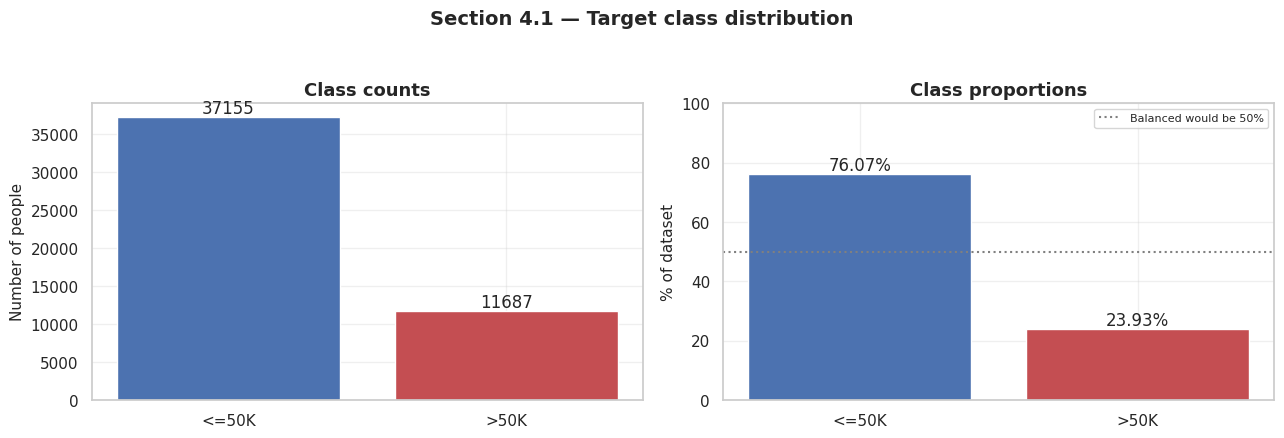

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

counts = adult_df[TARGET].value_counts()
bars = axes[0].bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
axes[0].bar_label(bars, fmt="%d")
axes[0].set_ylabel("Number of people")
axes[0].set_title("Class counts")

pcts = adult_df[TARGET].value_counts(normalize=True).mul(100)
bars = axes[1].bar(pcts.index, pcts.values, color=["#4C72B0", "#C44E52"])
axes[1].bar_label(bars, fmt="%.2f%%")
axes[1].set_ylabel("% of dataset")
axes[1].set_ylim(0, 100)
axes[1].axhline(50, color="grey", ls=":", label="Balanced would be 50%")
axes[1].set_title("Class proportions")
axes[1].legend(fontsize=8)

fig.suptitle("Section 4.1 — Target class distribution", y=1.04,
             fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("clf_eda_target", fig)
plt.show()

**Observation.** 37,155 people (76.07%) earn ≤50K and 11,687 (23.93%) earn
>50K — a 3.18 : 1 imbalance.

**Interpretation.** Analysed in full in Notebook 11 §3.5. The two consequences
carried forward: the split must be **stratified**, and every accuracy figure
must be read against the **76.07% floor** set by a model that always predicts
the majority class.

---
## 4.2 Distributions of the numerical features

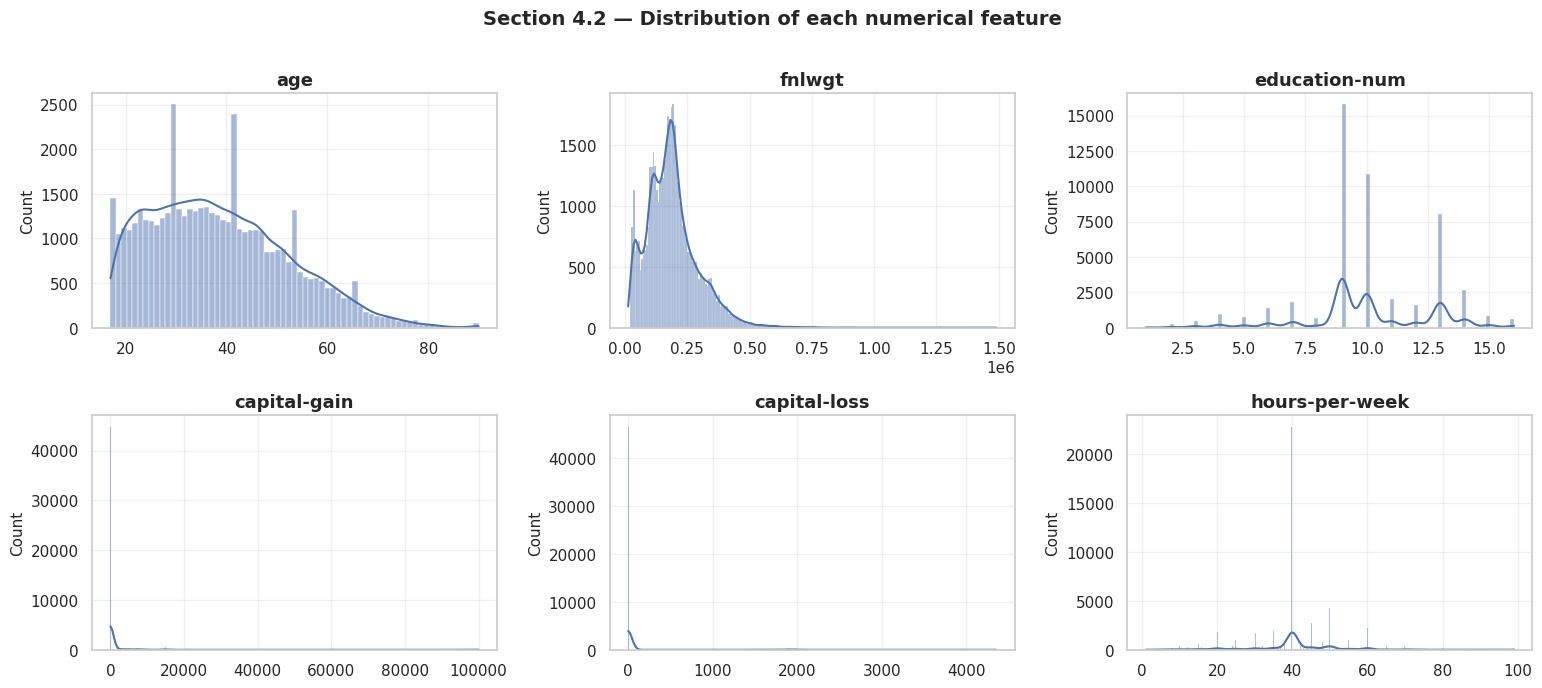

In [3]:
fig = plot_numeric_distributions(
    eda, NUMERIC_FEATURES, ncols=3,
    title="Section 4.2 — Distribution of each numerical feature",
)
save_figure("clf_eda_numeric_distributions", fig)
plt.show()

In [4]:
skew_table = pd.DataFrame({
    "Skewness": eda[NUMERIC_FEATURES].skew().round(2),
    "% exactly zero": [round(100 * (eda[c] == 0).mean(), 2) for c in NUMERIC_FEATURES],
    "Min": eda[NUMERIC_FEATURES].min(),
    "Max": eda[NUMERIC_FEATURES].max(),
}).sort_values("Skewness", ascending=False)

section("NUMERIC FEATURE SHAPE")
print(skew_table.to_string())

NUMERIC FEATURE SHAPE
                Skewness  % exactly zero    Min      Max
capital-gain       11.89           91.74      0    99999
capital-loss        4.57           95.33      0     4356
fnlwgt              1.44            0.00  12285  1490400
age                 0.56            0.00     17       90
hours-per-week      0.24            0.00      1       99
education-num      -0.32            0.00      1       16


**Observation.** Three distinct shapes appear:

* `age` is right-skewed but continuous and well-behaved.
* `education-num` and `hours-per-week` are strongly **spiked**:
  `hours-per-week` piles up at exactly 40, and `education-num` at the values
  for HS-grad and some-college.
* `capital-gain` and `capital-loss` are **extremely skewed and
  zero-inflated** — 91.7% and 95.3% of rows are exactly zero.

**Interpretation.** The zero-inflation of the capital variables is the same
structural pattern rainfall showed in the regression track, and it has the same
consequence: the informative signal is largely **whether the value is non-zero
at all**, not its magnitude. That is a direct argument for a binary
"has capital income" flag, which Notebook 13 creates.

The spike at exactly 40 hours reflects the standard full-time working week.
It means `hours-per-week` behaves partly like a category (full-time vs not)
rather than a smooth continuum — another engineering opportunity.

The ranges differ enormously: `fnlwgt` reaches 1.49 million while
`education-num` tops out at 16. **Scaling is therefore mandatory** for
Logistic Regression, KNN and SVC, all of which are sensitive to feature
magnitude.

---
## 4.3 Distributions of the categorical features

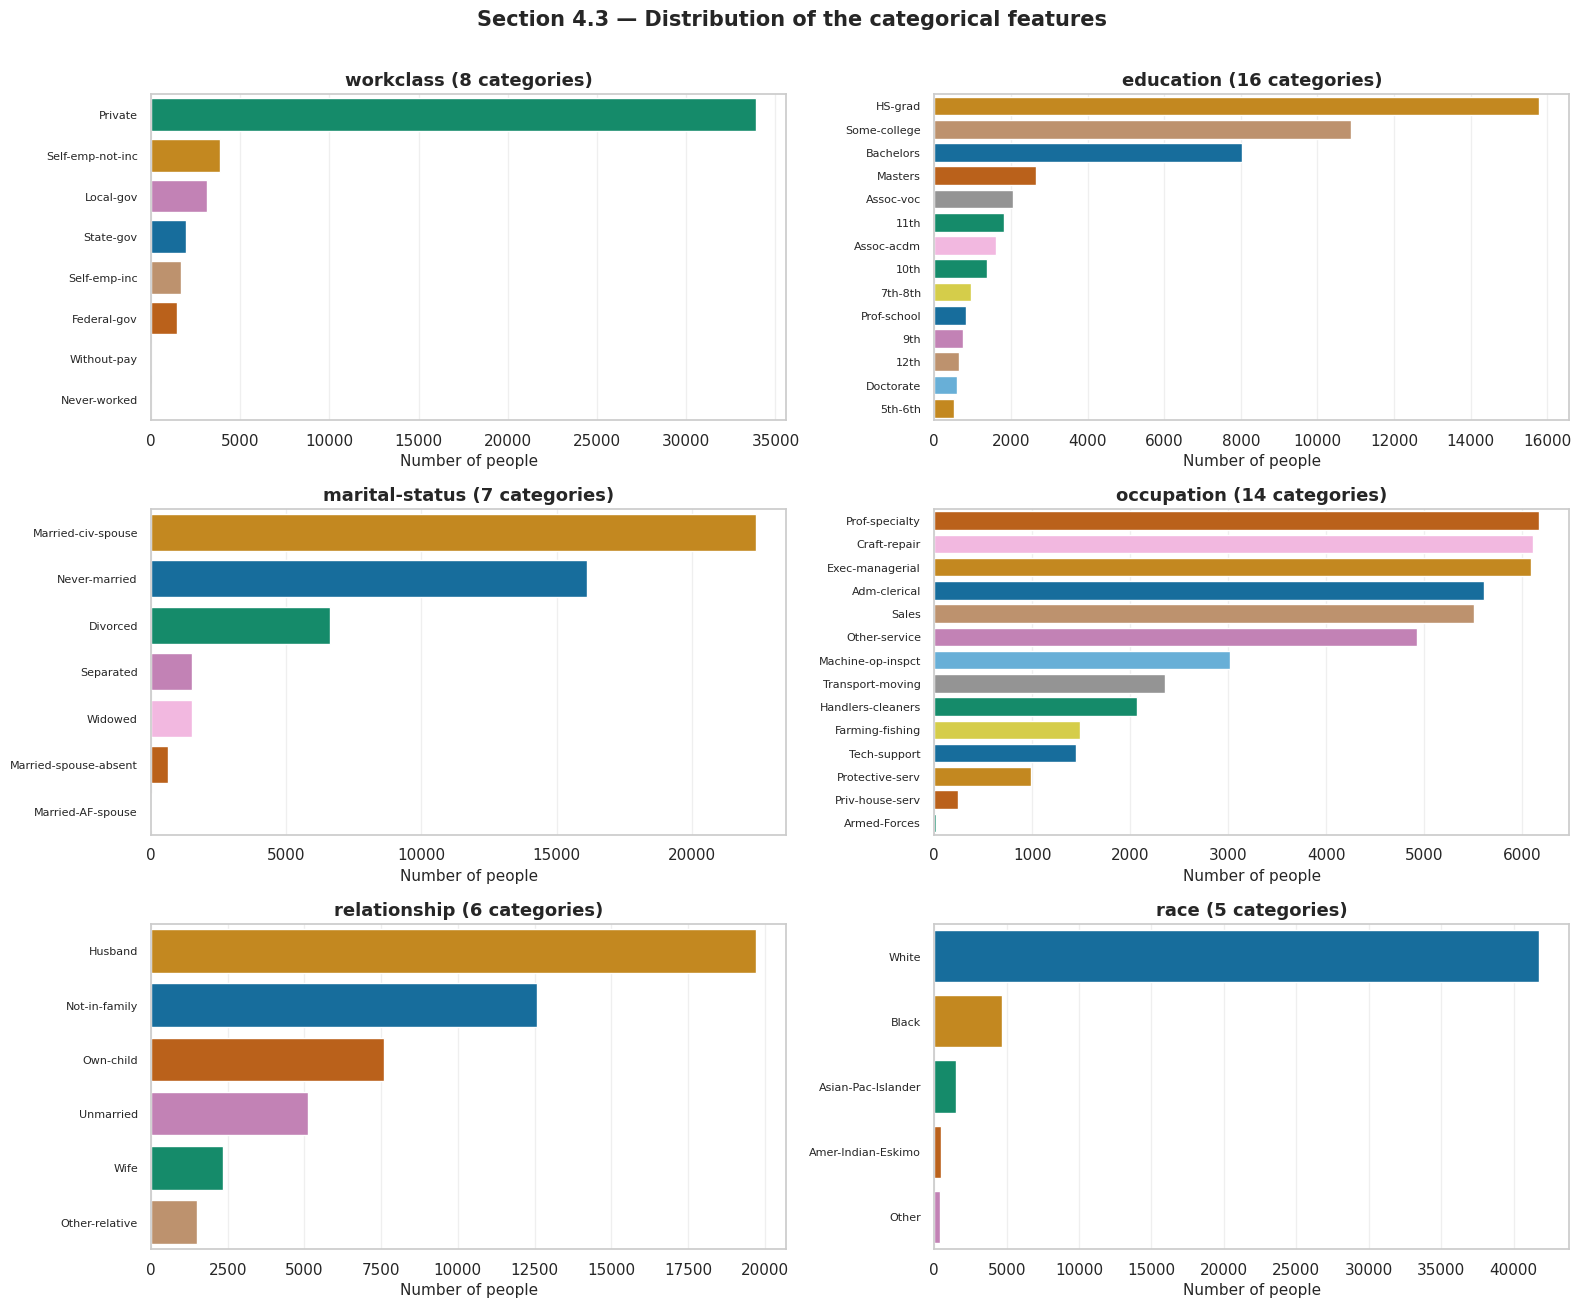

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
axes = axes.ravel()

for ax, col in zip(axes, ["workclass", "education", "marital-status",
                          "occupation", "relationship", "race"]):
    order = eda[col].value_counts().index[:14]
    sns.countplot(data=eda, y=col, order=order, hue=col, legend=False,
                  palette="colorblind", ax=ax)
    ax.set_title(f"{col} ({eda[col].nunique()} categories)")
    ax.set_xlabel("Number of people")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8)

fig.suptitle("Section 4.3 — Distribution of the categorical features",
             y=1.005, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_eda_categorical_distributions", fig)
plt.show()

In [6]:
section("CARDINALITY OF THE CATEGORICAL FEATURES")
card = pd.DataFrame({
    "Categories": [eda[c].nunique() for c in CATEGORICAL_FEATURES],
    "Most common": [eda[c].mode()[0] for c in CATEGORICAL_FEATURES],
    "Its share %": [round(100 * eda[c].value_counts(normalize=True).iloc[0], 1)
                    for c in CATEGORICAL_FEATURES],
}, index=CATEGORICAL_FEATURES).sort_values("Categories", ascending=False)
print(card.to_string())
print(f"\nTotal one-hot columns these would produce: {card['Categories'].sum()}")

CARDINALITY OF THE CATEGORICAL FEATURES
                Categories         Most common  Its share %
native-country          41       United-States         91.3
education               16             HS-grad         32.3
occupation              14      Prof-specialty         13.4
workclass                8             Private         73.6
marital-status           7  Married-civ-spouse         45.8
relationship             6             Husband         40.4
race                     5               White         85.5
sex                      2                Male         66.8

Total one-hot columns these would produce: 99


**Observation.** The categorical features are highly **unbalanced within
themselves**: `Private` covers 73.6% of `workclass`, `United-States`
covers 91.3% of `native-country`, and `White` 85.5% of `race`.
Cardinality ranges from 2 (`sex`) to 41 (`native-country`).

**Interpretation.** One-hot encoding these produces roughly a hundred columns,
most of them very sparse. Two consequences:

1. **Sparse one-hot columns hurt KNN in particular.** In a high-dimensional
   binary space, Euclidean distances between points become more uniform — the
   "curse of dimensionality" — which blunts the notion of a nearest neighbour.
   We should expect KNN to be competitive but not dominant here.
2. **`native-country` contributes 41 columns for very little signal**, since
   90% of people share one value. We consider grouping it in Notebook 13.

---
## 4.4 Correlation heatmap of the numerical features

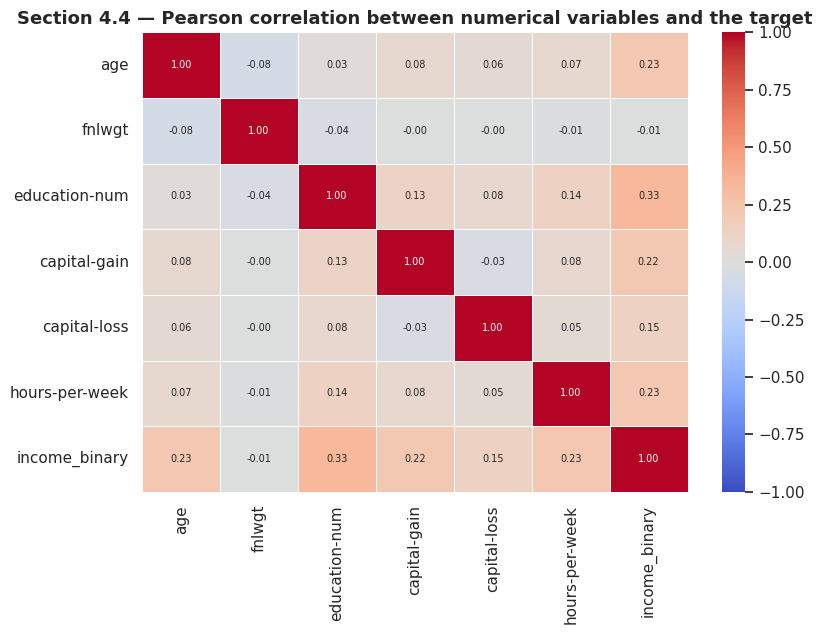

CORRELATION WITH THE TARGET (income_binary)
education-num     0.333
age               0.230
hours-per-week    0.228
capital-gain      0.223
capital-loss      0.148
fnlwgt           -0.006


In [7]:
corr_frame = eda[NUMERIC_FEATURES + ["income_binary"]]
fig, corr = plot_correlation_heatmap(
    corr_frame,
    title="Section 4.4 — Pearson correlation between numerical variables and the target",
    figsize=(8.5, 6.5),
)
save_figure("clf_eda_correlation", fig)
plt.show()

section("CORRELATION WITH THE TARGET (income_binary)")
print(corr["income_binary"].drop("income_binary")
      .sort_values(key=abs, ascending=False).round(3).to_string())

**Observation.** `education-num` shows the strongest correlation with income
(+0.333), followed by `age` (+0.230), `hours-per-week` (+0.228) and
`capital-gain` (+0.223). `fnlwgt` is essentially **uncorrelated (−0.006)**.
The predictors barely correlate with each other at all — the strongest
off-diagonal pairs are weak.

**Interpretation.**

* **`fnlwgt` is the important finding here.** It is the census *sampling
  weight* — how many people in the wider population this record represents. It
  is a property of the survey design, not of the person, and it has no
  causal or predictive relationship to their income. Its near-zero correlation
  confirms this. Notebook 13 drops it, with a written justification.
* **No multicollinearity among the numeric predictors**, which is a contrast
  with the regression track, where `Temperature` and `Dew point` correlated at
  0.91. Logistic Regression coefficients here will be more stable and more
  interpretable as a result.
* The same caution from the regression track applies: **Pearson's r measures
  only linear association**, and it is even less appropriate here because the
  target is binary. A low r does not license dropping a feature. `capital-gain`
  is a case in point — its correlation is modest, but §4.5 will show it is an
  almost perfect positive indicator when it is non-zero.

---
## 4.5 Feature vs target — numerical features

The rubric requires at least two meaningful feature-target analyses; we
present several, because different features separate the classes in quite
different ways.

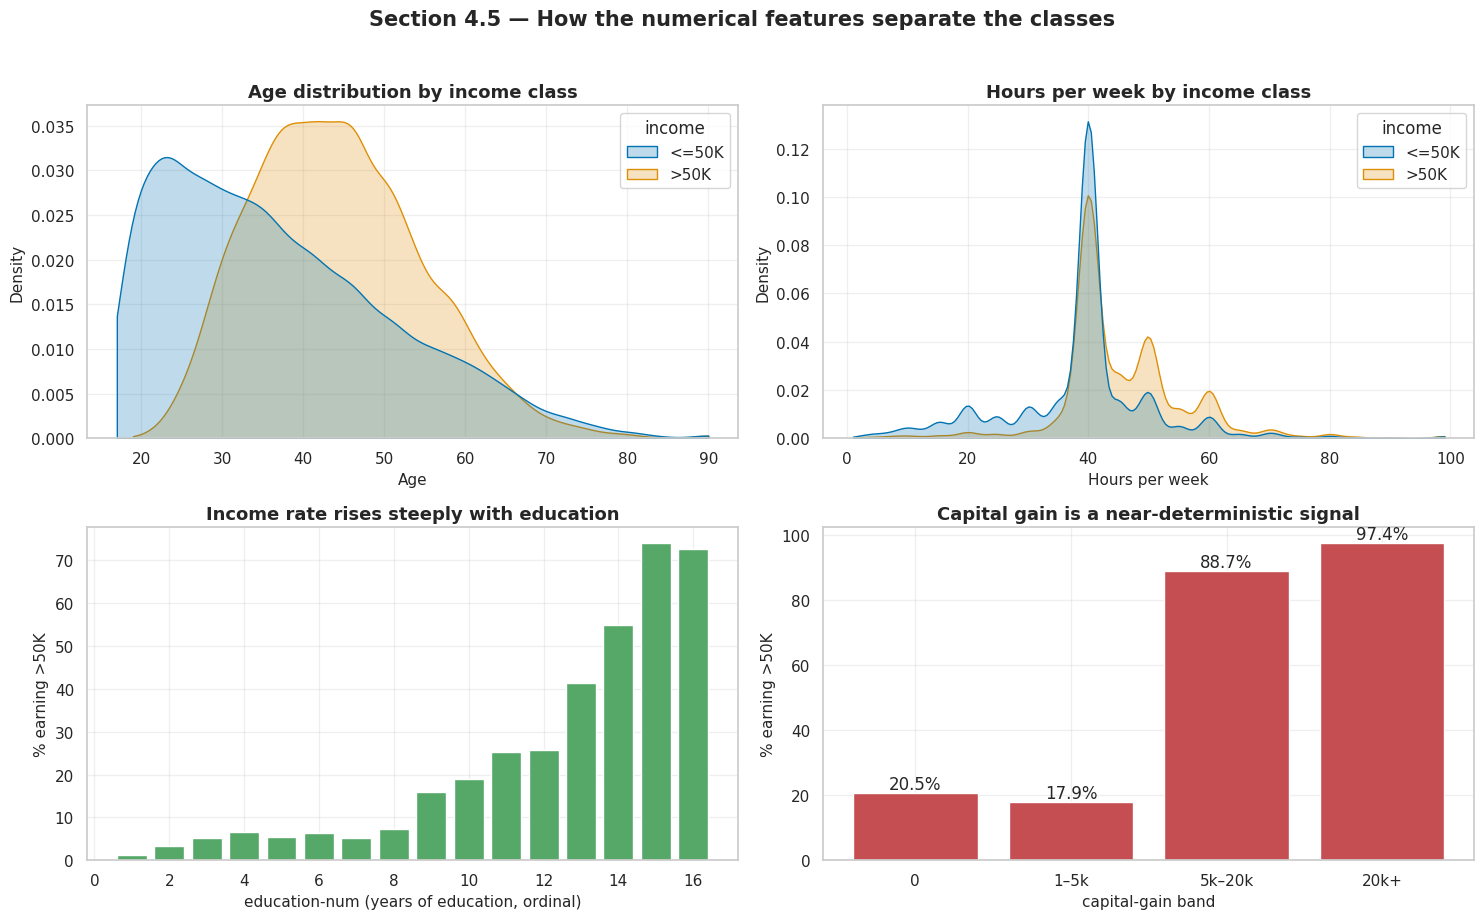

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.kdeplot(data=eda, x="age", hue=TARGET, fill=True, common_norm=False,
            palette="colorblind", ax=axes[0, 0], cut=0)
axes[0, 0].set_title("Age distribution by income class")
axes[0, 0].set_xlabel("Age")

sns.kdeplot(data=eda, x="hours-per-week", hue=TARGET, fill=True, common_norm=False,
            palette="colorblind", ax=axes[0, 1], cut=0)
axes[0, 1].set_title("Hours per week by income class")
axes[0, 1].set_xlabel("Hours per week")

edu_rate = (eda.groupby("education-num", observed=True)["income_binary"]
            .agg(["mean", "count"]).reset_index())
axes[1, 0].bar(edu_rate["education-num"], 100 * edu_rate["mean"], color="#55A868")
axes[1, 0].set_xlabel("education-num (years of education, ordinal)")
axes[1, 0].set_ylabel("% earning >50K")
axes[1, 0].set_title("Income rate rises steeply with education")

cap_group = pd.cut(eda["capital-gain"], bins=[-1, 0, 5000, 20000, 100000],
                   labels=["0", "1–5k", "5k–20k", "20k+"])
cap_rate = eda.groupby(cap_group, observed=True)["income_binary"].agg(["mean", "count"])
bars = axes[1, 1].bar(cap_rate.index.astype(str), 100 * cap_rate["mean"], color="#C44E52")
axes[1, 1].bar_label(bars, fmt="%.1f%%")
axes[1, 1].set_xlabel("capital-gain band")
axes[1, 1].set_ylabel("% earning >50K")
axes[1, 1].set_title("Capital gain is a near-deterministic signal")

fig.suptitle("Section 4.5 — How the numerical features separate the classes",
             y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_eda_numeric_vs_target", fig)
plt.show()

In [9]:
section("MEANS BY INCOME CLASS")
print(eda.groupby(TARGET, observed=True)[NUMERIC_FEATURES].mean().round(2).T.to_string())

print("\nProportion with any capital gain:")
print((eda.groupby(TARGET, observed=True)["capital-gain"]
       .apply(lambda s: 100 * (s > 0).mean()).round(1)).to_string())

print("\nIncome rate by capital-gain band:")
print(cap_rate.assign(**{"% >50K": (100 * cap_rate["mean"]).round(1)})
      [["count", "% >50K"]].to_string())

MEANS BY INCOME CLASS
income              <=50K       >50K
age                 36.87      44.28
fnlwgt          190039.57  188470.57
education-num        9.60      11.60
capital-gain       147.01    4042.24
capital-loss        54.15     193.53
hours-per-week      38.84      45.45

Proportion with any capital gain:
income
<=50K     4.2
>50K     21.3

Income rate by capital-gain band:
              count  % >50K
capital-gain               
0             44807    20.5
1–5k           1584    17.9
5k–20k         2070    88.7
20k+            381    97.4


**Observation.**

* **Age:** the >50K curve is shifted right and peaks in the 40s; the ≤50K
  curve peaks in the 20s. Mean age is 44.3 against 36.9. The >50K density
  falls away again past 60 — the relationship is **not monotonic**.
* **Hours:** both classes spike hard at 40, but the >50K group has
  substantially more mass above 40 (mean 45.5 vs 38.8 hours).
* **Education:** the income rate climbs steeply and consistently with
  `education-num`, reaching very high rates at the doctorate and professional-
  school levels.
* **Capital gain:** 21.3% of >50K earners report a capital gain against only
  4.2% of ≤50K earners, and in the highest band essentially **everyone** earns
  >50K.

**Interpretation.**

* The **non-monotonic age effect** matters for model choice. Logistic
  Regression fits a single coefficient for age, forcing "older always means
  more likely to earn >50K" — which is false past retirement. Trees and SVC
  with an RBF kernel can represent the peak-then-decline shape. This is a
  concrete, evidence-based reason to expect the non-linear models to do better,
  and it parallels the inverted-U temperature finding in the regression track.
* **Capital gain is nearly deterministic when present, and uninformative when
  absent.** That is a threshold relationship, not a slope, which is exactly why
  its Pearson correlation (0.223) understates it. A binary flag captures it
  directly.
* The concentration at exactly 40 hours means the useful distinction is
  largely **part-time / full-time / overtime**, supporting a banded feature.

---
## 4.6 Feature vs target — categorical features

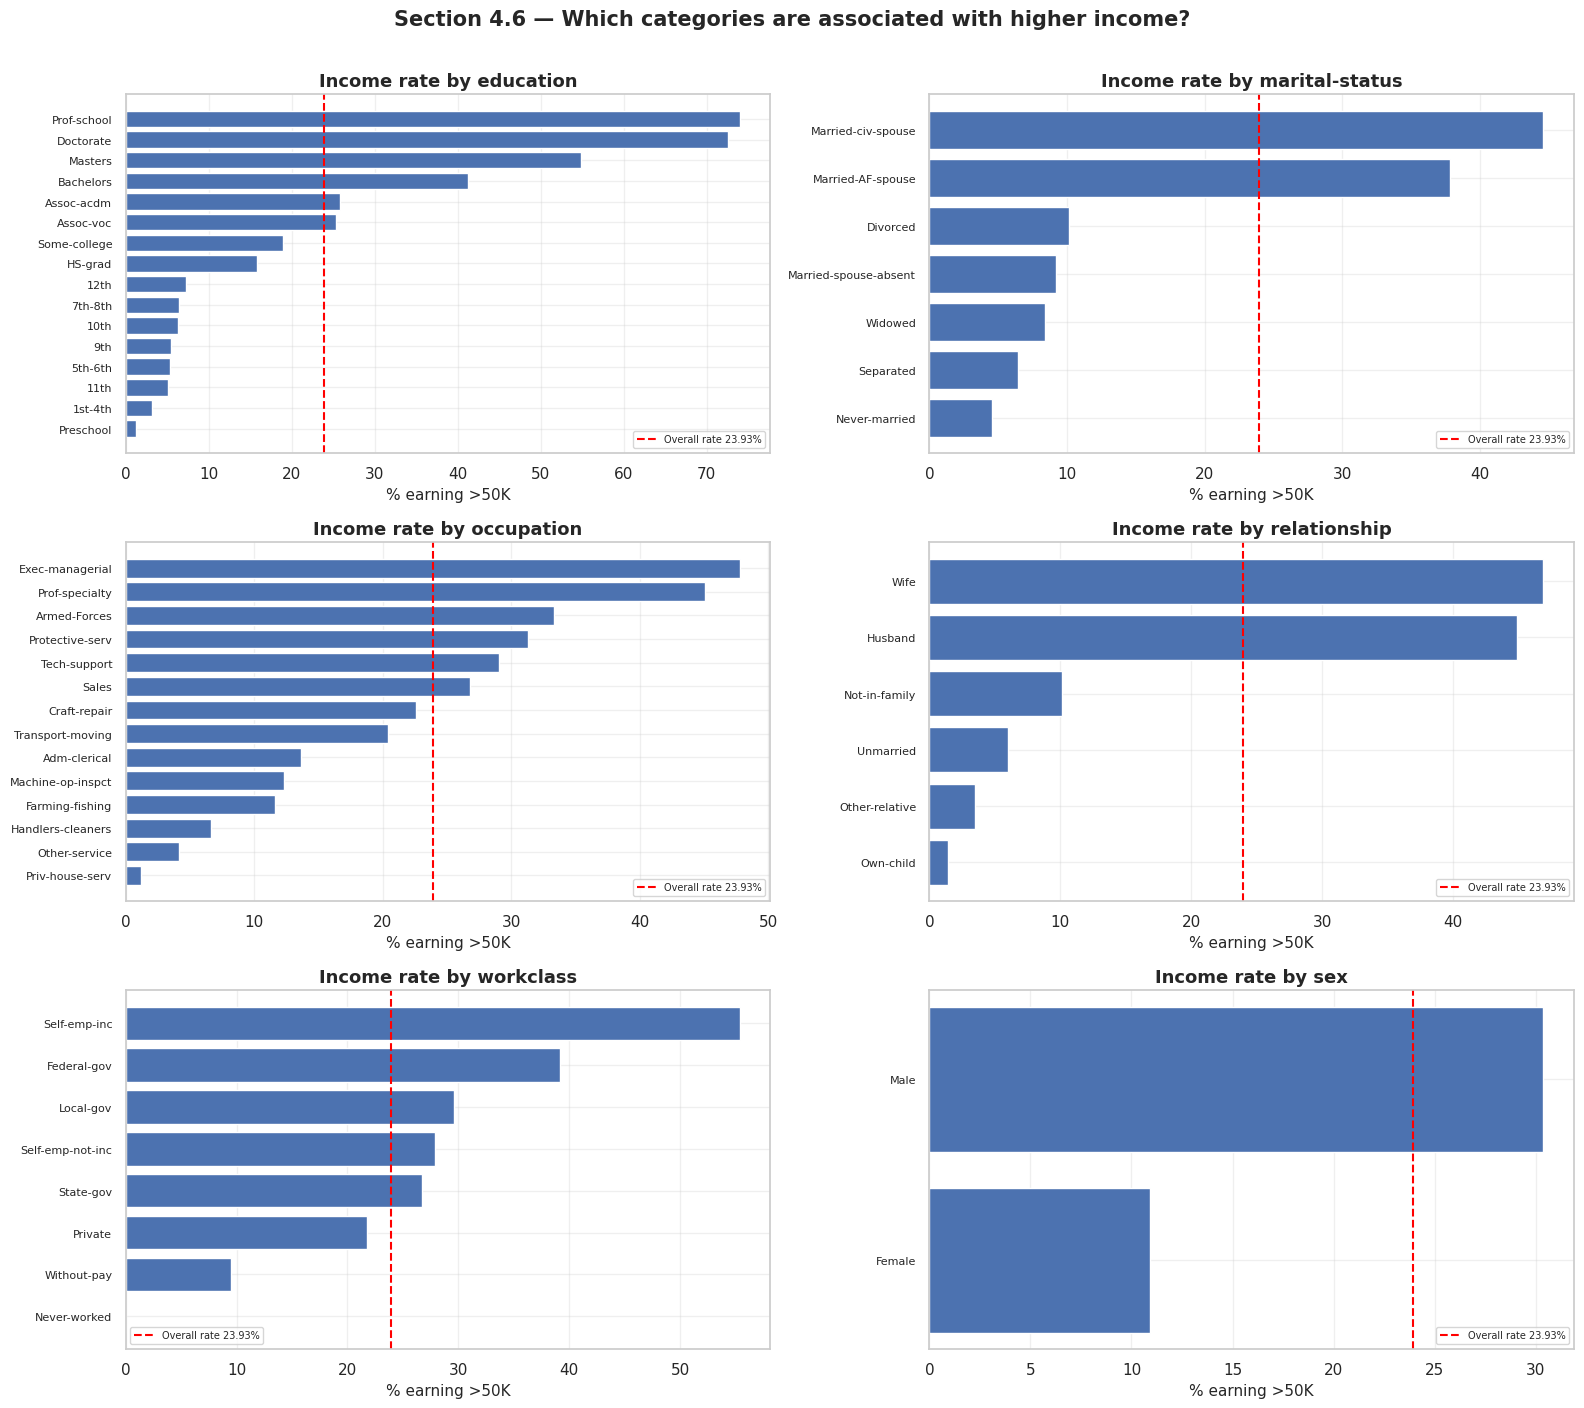

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.ravel()

for ax, col in zip(axes, ["education", "marital-status", "occupation",
                          "relationship", "workclass", "sex"]):
    rate = (eda.groupby(col, observed=True)["income_binary"]
            .agg(Rate="mean", Count="count")
            .sort_values("Rate", ascending=False))
    rate["Rate"] *= 100
    bars = ax.barh(rate.index, rate["Rate"], color="#4C72B0")
    ax.invert_yaxis()
    ax.axvline(23.93, color="red", ls="--", lw=1.5, label="Overall rate 23.93%")
    ax.set_xlabel("% earning >50K")
    ax.set_title(f"Income rate by {col}")
    ax.tick_params(axis="y", labelsize=8)
    ax.legend(fontsize=7)

fig.suptitle("Section 4.6 — Which categories are associated with higher income?",
             y=1.005, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_eda_categorical_vs_target", fig)
plt.show()

In [11]:
for col in ["education", "marital-status", "occupation", "relationship"]:
    section(f"INCOME RATE BY {col.upper()}")
    rate = (eda.groupby(col, observed=True)["income_binary"]
            .agg(People="count", Rate_pct=lambda s: round(100 * s.mean(), 1))
            .sort_values("Rate_pct", ascending=False))
    print(rate.head(5).to_string())
    print("   ...")
    print(rate.tail(3).to_string())
    print()

INCOME RATE BY EDUCATION
             People  Rate_pct
education                    
Prof-school     834      74.0
Doctorate       594      72.6
Masters        2657      54.9
Bachelors      8025      41.3
Assoc-acdm     1601      25.8
   ...
           People  Rate_pct
education                  
11th         1812       5.1
1st-4th       247       3.2
Preschool      83       1.2

INCOME RATE BY MARITAL-STATUS
                       People  Rate_pct
marital-status                         
Married-civ-spouse      22379      44.6
Married-AF-spouse          37      37.8
Divorced                 6633      10.1
Married-spouse-absent     628       9.2
Widowed                  1518       8.4
   ...
                People  Rate_pct
marital-status                  
Widowed           1518       8.4
Separated         1530       6.5
Never-married    16117       4.5

INCOME RATE BY OCCUPATION
                 People  Rate_pct
occupation                       
Exec-managerial    6086      47.8
Prof-s

**Observation.** The categorical features separate the classes far more
sharply than the numeric ones:

* **Education:** `Prof-school` 74.0% and `Doctorate` 72.6% against
  `Preschool` 1.2% — a range of more than 70 percentage points.
* **Marital status:** `Married-civ-spouse` 44.6% against `Never-married`
  4.5% — a tenfold difference.
* **Occupation:** `Exec-managerial` 47.8% and `Prof-specialty` 45.1% against
  `Priv-house-serv` 1.2%.
* **Relationship:** `Wife` 46.9% and `Husband` 44.9% against `Own-child` 1.5%.

**Interpretation.**

* These are the strongest predictors in the dataset, which means **encoding
  quality matters more than scaling here**. One-hot encoding preserves these
  distinctions; label encoding would impose a meaningless numeric order on them.
* **The marital-status effect is the clearest case of confounding in the
  dataset, and it deserves care.** Being married does not cause a higher
  salary. Marriage correlates with age, which correlates with career stage.
  Furthermore, the $50,000 threshold is applied to an individual whose
  household context differs systematically by marital status. A model will use
  this variable because it predicts well; that is not the same as it explaining
  anything.
* **`relationship` and `marital-status` overlap heavily** — `Husband`/`Wife`
  largely restates `Married-civ-spouse`. This is categorical
  multicollinearity. It will not damage tree models, but it does mean
  Logistic Regression coefficients on these two variables cannot be read
  individually.

---
## 4.7 Grouped analysis — where the interactions are

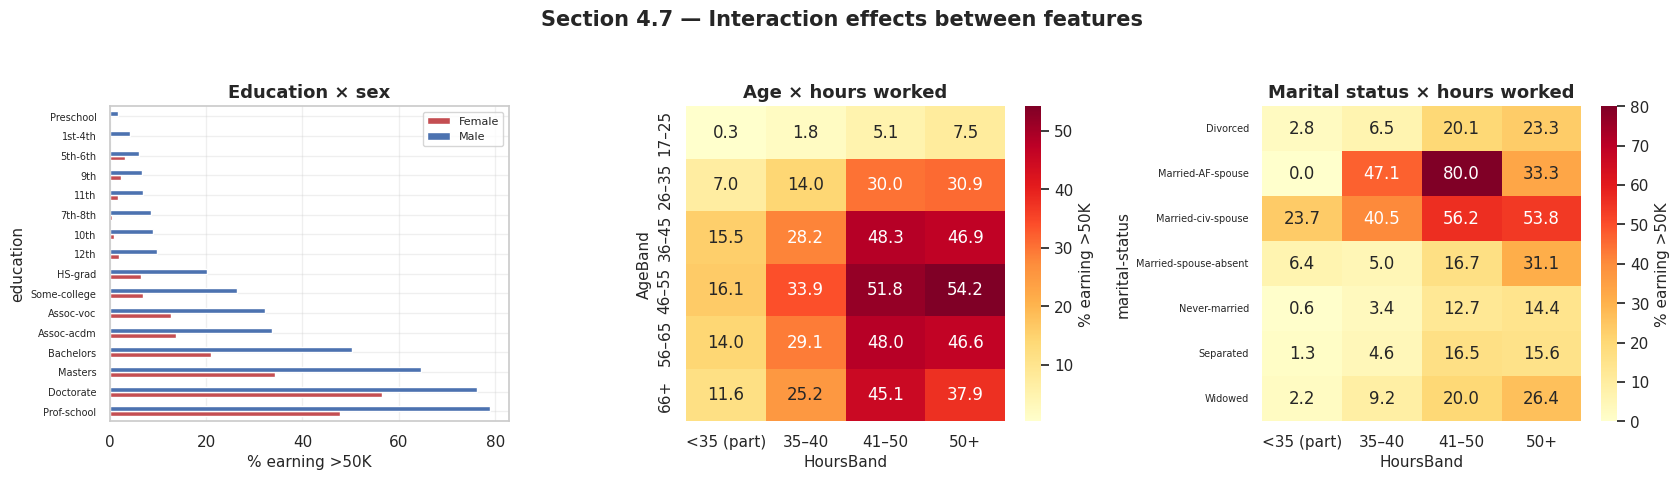

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

pivot = (eda.pivot_table(index="education", columns="sex",
                         values="income_binary", aggfunc="mean")
         .mul(100).round(1).sort_values("Male", ascending=False))
pivot.plot(kind="barh", ax=axes[0], color=["#C44E52", "#4C72B0"])
axes[0].set_xlabel("% earning >50K")
axes[0].set_title("Education × sex")
axes[0].tick_params(axis="y", labelsize=7)
axes[0].legend(title="", fontsize=8)

age_band = pd.cut(eda["age"], bins=[16, 25, 35, 45, 55, 65, 100],
                  labels=["17–25", "26–35", "36–45", "46–55", "56–65", "66+"])
hours_band = pd.cut(eda["hours-per-week"], bins=[0, 34, 40, 50, 100],
                    labels=["<35 (part)", "35–40", "41–50", "50+"])
grid = (eda.assign(AgeBand=age_band, HoursBand=hours_band)
        .pivot_table(index="AgeBand", columns="HoursBand",
                     values="income_binary", aggfunc="mean", observed=True)
        .mul(100).round(1))
sns.heatmap(grid, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1],
            cbar_kws={"label": "% earning >50K"})
axes[1].set_title("Age × hours worked")

marital_hours = (eda.assign(HoursBand=hours_band)
                 .pivot_table(index="marital-status", columns="HoursBand",
                              values="income_binary", aggfunc="mean", observed=True)
                 .mul(100).round(1))
sns.heatmap(marital_hours, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[2],
            cbar_kws={"label": "% earning >50K"})
axes[2].set_title("Marital status × hours worked")
axes[2].tick_params(axis="y", labelsize=7)

fig.suptitle("Section 4.7 — Interaction effects between features",
             y=1.04, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_eda_interactions", fig)
plt.show()

In [13]:
section("INCOME RATE BY AGE BAND AND HOURS WORKED (%)")
print(grid.to_string())

INCOME RATE BY AGE BAND AND HOURS WORKED (%)
HoursBand  <35 (part)  35–40  41–50   50+
AgeBand                                  
17–25             0.3    1.8    5.1   7.5
26–35             7.0   14.0   30.0  30.9
36–45            15.5   28.2   48.3  46.9
46–55            16.1   33.9   51.8  54.2
56–65            14.0   29.1   48.0  46.6
66+              11.6   25.2   45.1  37.9


**Observation.** The age × hours heatmap is not a simple gradient in either
direction. Working 50+ hours raises the income rate substantially at every age,
but the *size* of that lift depends on age: it is small for the youngest band
and much larger in middle age. Similarly, the education × sex panel shows the
gap between men and women at the same education level varying by level.

**Interpretation.** These are **interaction effects** — the effect of one
variable depends on the value of another. This matters directly for the model
comparison in Notebook 14:

* **Logistic Regression cannot represent interactions** unless we construct
  them by hand. It can add an age effect and add an hours effect, but not
  multiply them.
* **Decision Trees model interactions natively** by splitting on one variable
  and then another within that branch.
* **SVC with an RBF kernel** can capture them implicitly through the kernel.
* **Gaussian Naive Bayes explicitly assumes features are conditionally
  independent given the class** — which this plot shows is false. We should
  expect Naive Bayes to underperform here, and we now have a specific,
  measured reason rather than a general one.

The education × sex panel also reinforces the ethical point from Notebook 10
§1.7: the model will learn these disparities. Its accuracy will partly come
from reproducing them.

---
## 4.8 EDA summary — what we take into modelling

| # | Finding | Consequence |
|---|---|---|
| 1 | 76.07% / 23.93% class split | Stratified split; weighted F1 as headline metric |
| 2 | `fnlwgt` correlates −0.006 with income; it is a survey weight | **Drop it** (NB 13) |
| 3 | `capital-gain` is near-deterministic when non-zero, 91.7% zeros | Add a binary "has capital income" flag (NB 13) |
| 4 | `hours-per-week` spikes hard at 40 | Add banded hours feature (NB 13) |
| 5 | Age effect is non-monotonic (peaks in the 40s) | Favours trees and RBF-SVC over Logistic Regression |
| 6 | Education, marital status and occupation separate classes strongly | Encoding quality matters most; one-hot required |
| 7 | Clear interactions (age × hours, education × sex) | **Predicts Gaussian NB will underperform** — its independence assumption is violated |
| 8 | `relationship` largely restates `marital-status` | Logistic coefficients on these are not individually interpretable |
| 9 | Feature ranges differ by 5 orders of magnitude | Scaling mandatory for Logistic Regression, KNN, SVC |
| 10 | ~100 sparse one-hot columns after encoding | May blunt KNN's distance metric |

**Hypotheses carried into Notebook 14** (to be tested, not assumed):

1. **Gaussian Naive Bayes should be weakest**, because finding 7 directly
   violates its conditional-independence assumption.
2. **SVC should be strong**, since an RBF kernel can represent both the
   non-monotonic age effect (finding 5) and the interactions (finding 7).
3. **Logistic Regression should be a solid but limited baseline** — limited by
   finding 5, but helped by the banded features we add in Notebook 13.
4. **The Decision Tree is the hardest to call.** It models interactions
   natively, which favours it, but left unpruned it will memorise the training
   set — and with ~100 sparse one-hot columns there is a great deal to
   memorise. Whether its flexibility or its variance dominates is an empirical
   question, not one we can settle from the EDA.
5. **KNN should be competitive but not dominant**, blunted by finding 10.

---
## Handover to Notebook 13

In [14]:
save_artifact(adult_df, "clf_12_eda")

print("\nNotebook 12 complete.")
print("Next: 13_classification_cleaning_feature_engineering_split.ipynb")

[saved]  artifacts/clf_12_eda.joblib

Notebook 12 complete.
Next: 13_classification_cleaning_feature_engineering_split.ipynb
